# BlindCore BlindJSONB NoSQL Demo: Encrypted Document Containment, Lifecycle & Single-Query Blind Naive Bayes

**Target Markets:** Enterprise Email Security, Threat Intelligence, Healthcare/Fintech Semi-Structured JSON Telemetry  
**Workflow:** Create a schema-less `BlindJSONB` encrypted collection (`k_tok=8, k_num=8, k_min_tkms=2`) -> Ingest sparse Bag-of-Words phishing & legit email JSON docs -> Prove **zero plaintext keys, paths, or counts** in raw SQL -> Verify Postgres `@>` `CONTAINS`, `UPSERT` v2 superseding, `TOMBSTONE` deletion, and `k_min_tkms` single-record anti-extraction -> Run the **entire `sklearn.naive_bayes.MultinomialNB(alpha=1.0)` Bag-of-Words training + blind `WEIGHTED_SUM` cohort scoring pipeline inside ONE SINGLE HTTP QUERY (`op: "SKLEARN_MNB"`)** with `< 1e-12` log-prob parity and an `NSAU0001` cryptographic receipt over TLS 1.3 on AlmaLinux 10.3 ARM64.

### Key Architectural Guarantees Verified Live
- **Zero-Plaintext Schema-Less NoSQL:** Documents are shredded into fixed-budget HMAC containment slots (`k_tok=8`), fixed-budget lattice-encrypted numeric leaf slots (`k_num=8`), and an authenticated encrypted blob -- hiding both field values and document sparsity.
- **Immutable Log-Structured Lifecycle (`UPSERT` & `TOMBSTONE`):** Updating an entity (`UPSERT` v2) atomically supersedes v1 in both `CONTAINS` and `SUM`; `TOMBSTONE` removes the document from active containment, aggregates, and `LATEST` lookups (`HTTP 404`).
- **Cryptographic Anti-Extraction (`k_min_tkms`):** Attempting to extract an individual document's encrypted count via `WEIGHTED_SUM` with a one-hot mask (`[1, 0, ...]`) is deterministically blocked with `HTTP 422`.
- **Single-Query Blind `sklearn` Training & Scoring (`op: "SKLEARN_MNB"`):** Replaces `18` sequential HTTP calls (`2 CONTAINS + 8 SUM + 8 WEIGHTED_SUM`) with **1 single fused ARM64 query** using zero-allocation expand-accumulate and batched `2-of-3` `TKMS` decryption -- reproducing `sklearn.naive_bayes.MultinomialNB(alpha=1.0)` `feature_log_prob_` and `class_log_prior_` to `< 1e-12` and scoring held-out encrypted cohorts with `0` integer error.


In [1]:
import hashlib
import hmac
import json
import os
import struct
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.naive_bayes import MultinomialNB

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "python" / "blindcore_sdk.py").is_file():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "python" / "blindcore_sdk.py").is_file(), (
    "Run Jupyter from blindcore-sdk/ or blindcore-sdk/notebooks/"
)
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blindcore_sdk import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)


def verify_nsau0001_jsonb_table(table: str, k_tok: int, k_num: int, resp: dict) -> tuple[bool, str]:
    assert resp.get("receipt_magic") == "NSAU0001"
    srv_hex = str(resp.get("receipt_hex", ""))
    preimage = (
        b"NSAU0001:BLIND:JSONB_TABLE:"
        + table.encode("ascii")
        + struct.pack("<Q", int(k_tok))
        + bytes([int(k_tok), int(k_num)])
    )
    local_hex = hashlib.sha256(preimage).hexdigest()
    return hmac.compare_digest(local_hex, srv_hex), local_hex


def verify_nsau0001_jsonb_contains(resp: dict) -> tuple[bool, str]:
    assert resp.get("receipt_magic") == "NSAU0001"
    srv_hex = str(resp.get("receipt_hex", ""))
    h = hashlib.sha256()
    for d in resp.get("docs", []):
        h.update(bytes.fromhex(str(d["doc_id_tok_hex"])))
        h.update(bytes.fromhex(str(d["doc_blob_hex"])))
    preimage = (
        b"NSAU0001:BLIND:JSONB_CONTAINS:"
        + str(resp["table"]).encode("ascii")
        + struct.pack("<Q", int(resp["matched_count"]))
        + h.digest()
    )
    local_hex = hashlib.sha256(preimage).hexdigest()
    return hmac.compare_digest(local_hex, srv_hex), local_hex


def verify_nsau0001_jsonb_sum(resp: dict) -> tuple[bool, str]:
    assert resp.get("receipt_magic") == "NSAU0001"
    srv_hex = str(resp.get("receipt_hex", ""))
    op_b = str(resp["op"]).encode("ascii")
    tbl_b = str(resp["table"]).encode("ascii")
    cnt_b = struct.pack("<Q", int(resp["matched_docs"]))
    ct_bytes = bytes.fromhex(str(resp["ct_result_hex"]))
    preimage = b"NSAU0001:BLIND:" + op_b + b":" + tbl_b + cnt_b + ct_bytes
    local_hex = hashlib.sha256(preimage).hexdigest()
    return hmac.compare_digest(local_hex, srv_hex), local_hex



def verify_nsau0001_jsonb_sklearn_mnb(resp: dict) -> tuple[bool, str]:
    assert resp.get("receipt_magic") == "NSAU0001"
    srv_hex = str(resp.get("receipt_hex", ""))
    h = hashlib.sha256()
    for c in resp.get("class_doc_counts", []):
        h.update(struct.pack("<Q", int(c)))
    for row in resp.get("feature_counts", []):
        for fc in row:
            h.update(struct.pack("<q", int(fc)))
    for w in resp.get("log_odds_weights", []):
        h.update(struct.pack("<q", int(w)))
    for sc in resp.get("scores", []):
        h.update(struct.pack("<Q", int(sc["matched_docs"])))
        h.update(struct.pack("<q", int(sc["raw_int_score"])))
        h.update(bytes.fromhex(str(sc["ct_result_hex"])))
    preimage = (
        b"NSAU0001:BLIND:JSONB_SKLEARN_MNB:"
        + str(resp["table"]).encode("ascii")
        + struct.pack("<Q", int(resp["rows_scanned"]))
        + h.digest()
    )
    local_hex = hashlib.sha256(preimage).hexdigest()
    return hmac.compare_digest(local_hex, srv_hex), local_hex


t0_hb = time.perf_counter()
hb = client.query_json("SELECT 1 AS ok")
hb_rtt_ms = (time.perf_counter() - t0_hb) * 1000.0
assert hb["rows"] == [[1]]
hb_eng_us = int(hb.get("elapsed_us", 0))
print(f"Client   : {client!r}")
print(
    f"Heartbeat: OK | TLS 1.3 RTT={hb_rtt_ms:.2f} ms | "
    f"ARM64 engine={hb_eng_us} us | Network={max(0.0, hb_rtt_ms - hb_eng_us / 1000.0):.2f} ms"
)


Client   : BlindCoreClient(endpoint='https://api.blindlabs.ai', token='<redacted>', timeout=30.0)
Heartbeat: OK | TLS 1.3 RTT=534.91 ms | ARM64 engine=40 us | Network=534.87 ms


## 1. Create `BlindJSONB` Collection & Ingest Sparse Encrypted Email Docs

We declare a fresh timestamped `BlindJSONB` collection (`k_tok=8, k_num=8, allow_low_entropy_tokens=True, k_min_tkms=2`) via `POST /api/v1/blind/jsonb/table`, then ingest `16` sparse, heterogeneous Bag-of-Words JSON documents (`8` `"phishing"` and `8` `"legit"` emails) containing vocabulary counts under `bow` (`wire`, `urgent`, `verify`, `invoice`) plus optional schema-less attributes (`channel`, `has_link`, `dept`). Zero-count words are omitted on many documents to exercise genuine sparse JSONB shredding with fixed-size dummy-slot padding.


In [2]:
COLL_NAME = f"blind_jsonb_phish_v1_{time.strftime('%Y%m%d_%H%M%S', time.gmtime())}"
K_TOK = 8
K_NUM = 8
K_MIN_TKMS = 2
VOCAB = ["wire", "urgent", "verify", "invoice"]

t0_cr = time.perf_counter()
cr_res = client.create_blind_jsonb_table(
    COLL_NAME,
    k_tok=K_TOK,
    k_num=K_NUM,
    allow_low_entropy_tokens=True,
    k_min_tkms=K_MIN_TKMS,
)
cr_rtt_ms = (time.perf_counter() - t0_cr) * 1000.0
assert cr_res.get("status") == "ok"
assert cr_res.get("plaintext_stored") is False
assert cr_res.get("k_tok") == K_TOK and cr_res.get("k_num") == K_NUM and cr_res.get("k_min_tkms") == K_MIN_TKMS
cr_ok, cr_hex = verify_nsau0001_jsonb_table(COLL_NAME, K_TOK, K_NUM, cr_res)
assert cr_ok, "NSAU0001 JSONB_TABLE receipt verification failed"

receipt_ledger = [("JSONB_TABLE", K_TOK, cr_res["receipt_magic"], cr_hex, cr_ok)]

# 16 sparse Bag-of-Words email JSON docs (8 phishing, 8 legit) with heterogeneous keys.
TRAIN_DOCS = [
    ("phish_01", {"label": "phishing", "channel": "ext", "bow": {"wire": 4, "urgent": 3, "verify": 2}}),
    ("phish_02", {"label": "phishing", "has_link": True, "bow": {"wire": 3, "urgent": 2, "invoice": 1}}),
    ("phish_03", {"label": "phishing", "bow": {"wire": 5, "urgent": 4, "verify": 3, "invoice": 1}}),
    ("phish_04", {"label": "phishing", "channel": "ext", "bow": {"wire": 2, "verify": 4, "urgent": 2}}),
    ("phish_05", {"label": "phishing", "bow": {"urgent": 5, "verify": 3, "invoice": 2}}),
    ("phish_06", {"label": "phishing", "has_link": True, "bow": {"wire": 6, "urgent": 3, "verify": 2, "invoice": 1}}),
    ("phish_07", {"label": "phishing", "bow": {"wire": 3, "verify": 5, "urgent": 1}}),
    ("phish_08", {"label": "phishing", "channel": "ext", "bow": {"wire": 4, "urgent": 4, "verify": 2, "invoice": 2}}),
    ("legit_01", {"label": "legit", "dept": "ap", "bow": {"invoice": 5, "verify": 1}}),
    ("legit_02", {"label": "legit", "bow": {"invoice": 4, "wire": 1, "urgent": 1}}),
    ("legit_03", {"label": "legit", "dept": "finance", "bow": {"invoice": 6, "verify": 2}}),
    ("legit_04", {"label": "legit", "bow": {"invoice": 3, "wire": 1, "verify": 1}}),
    ("legit_05", {"label": "legit", "dept": "ops", "bow": {"invoice": 5, "urgent": 1}}),
    ("legit_06", {"label": "legit", "bow": {"invoice": 4, "verify": 1, "wire": 0}}),
    ("legit_07", {"label": "legit", "dept": "ap", "bow": {"invoice": 7, "urgent": 1, "verify": 1}}),
    ("legit_08", {"label": "legit", "bow": {"invoice": 5, "wire": 1}}),
]

ingest_rows = [
    {"seal_doc": {"entity_id": eid, "doc_json": json.dumps(doc, separators=(",", ":"))}}
    for eid, doc in TRAIN_DOCS
]

t0_ing = time.perf_counter()
ing_res = client.ingest_blind_jsonb(COLL_NAME, ingest_rows)
ing_rtt_ms = (time.perf_counter() - t0_ing) * 1000.0
assert ing_res.get("status") == "ok"
assert ing_res.get("rows_ingested") == len(TRAIN_DOCS)
assert ing_res.get("plaintext_stored") is False
assert ing_res.get("receipt_magic") == "NSAU0001" and len(str(ing_res.get("receipt_hex", ""))) == 64

print(f"Collection : {COLL_NAME} (k_tok={K_TOK}, k_num={K_NUM}, k_min_tkms={K_MIN_TKMS})")
print(f"Create RTT : {cr_rtt_ms:.2f} ms | NSAU0001 Table Receipt={cr_hex[:16]}...{cr_hex[-8:]} (MATCH)")
print(
    f"Ingested   : {ing_res['rows_ingested']} sparse encrypted JSON docs "
    f"({ing_res['bytes_ingested']:,} bytes) | plaintext_stored={ing_res['plaintext_stored']} | "
    f"RTT={ing_rtt_ms:.2f} ms"
)


Collection : blind_jsonb_phish_v1_20261120_114438 (k_tok=8, k_num=8, k_min_tkms=2)
Create RTT : 171.23 ms | NSAU0001 Table Receipt=8377ab858e25cceb...9cb011de (MATCH)
Ingested   : 16 sparse encrypted JSON docs (18,240 bytes) | plaintext_stored=False | RTT=233.47 ms


## 2. Zero-Plaintext Storage Audit (`SELECT * LIMIT 3`)

We query the underlying SQL table directly (`SELECT * FROM <collection> LIMIT 3`) to verify what an attacker with raw database read access or disk-dump privileges sees:
1. **Zero plaintext keys or values:** None of `"wire"`, `"urgent"`, `"verify"`, `"invoice"`, `"phishing"`, `"legit"`, `"label"`, `"bow"`, or RFC 6901 paths (`"/bow/wire"`, `"/label"`) appear in any stored column text or decoded raw bytes.
2. **Fixed-size dummy padding hides document sparsity:** Regardless of how many sparse fields a JSON document contains, `_tok_slots` is always `k_tok * 32 = 256` bytes and `_num_slots` is always `k_num * 112 = 896` bytes.


In [3]:
t0_sql = time.perf_counter()
raw_sql = client.query_json(f"SELECT * FROM {COLL_NAME} LIMIT 3")
raw_sql_rtt_ms = (time.perf_counter() - t0_sql) * 1000.0
assert len(raw_sql["rows"]) == 3, f"Expected 3 rows, got {len(raw_sql['rows'])}"

col_idx = {name: i for i, name in enumerate(raw_sql["columns"])}
HEX_COLS = ["_doc_id_tok", "_doc_blob", "_tok_slots", "_num_slots"]
FORBIDDEN_STRINGS = [
    "wire", "urgent", "verify", "invoice",
    "phishing", "legit", "label", "bow",
    "/bow/wire", "/bow/urgent", "/bow/verify", "/bow/invoice", "/label",
    "channel", "dept", "has_link", "phish_0", "legit_0",
]

leaks = 0
cells_audited = 0
for row in raw_sql["rows"]:
    tok_bytes = bytes.fromhex(str(row[col_idx["_tok_slots"]]))
    num_bytes = bytes.fromhex(str(row[col_idx["_num_slots"]]))
    assert len(tok_bytes) == K_TOK * 32, f"Expected {K_TOK * 32}B tok_slots, got {len(tok_bytes)}"
    assert len(num_bytes) == K_NUM * 112, f"Expected {K_NUM * 112}B num_slots, got {len(num_bytes)}"

    for cname in HEX_COLS:
        cell_hex = str(row[col_idx[cname]])
        raw_b = bytes.fromhex(cell_hex)
        low_hex = cell_hex.lower()
        low_raw = raw_b.lower()
        for pat in FORBIDDEN_STRINGS:
            if pat.encode("ascii") in low_raw or pat in low_hex:
                leaks += 1
        # Verify no plaintext JSON key:count substrings or 8-byte signed count headers leak in _doc_blob.
        if cname == "_doc_blob":
            for count_pat in (b":4", b":3", b":5", b":6", b":7"):
                if b'"wire"' + count_pat in raw_b or b'"invoice"' + count_pat in raw_b:
                    leaks += 1
        cells_audited += 1

assert leaks == 0, f"Plaintext leak detected in BlindJSONB storage: {leaks}"

print(f"Raw SQL Audit: SELECT * FROM {COLL_NAME} LIMIT 3")
print(
    f"  Engine={raw_sql.get('elapsed_us', 0)} us | RTT={raw_sql_rtt_ms:.2f} ms | "
    f"Encrypted cells audited={cells_audited} | Plaintext key/path/count leaks={leaks}"
)
print("+--------------------+----------------------+----------------------+----------------------+")
print("| _doc_id_tok (32B)  | _doc_blob (AEAD)     | _tok_slots (256B)    | _num_slots (896B)    |")
print("+--------------------+----------------------+----------------------+----------------------+")
for row in raw_sql["rows"]:
    d_id = str(row[col_idx["_doc_id_tok"]])
    d_bl = str(row[col_idx["_doc_blob"]])
    d_tk = str(row[col_idx["_tok_slots"]])
    d_nm = str(row[col_idx["_num_slots"]])
    print(
        f"| {d_id[:12]}..     | {d_bl[:10]}.. ({len(d_bl)//2:3d}B) | "
        f"{d_tk[:10]}.. ({len(d_tk)//2:3d}B) | {d_nm[:10]}.. ({len(d_nm)//2:3d}B) |"
    )
print("+--------------------+----------------------+----------------------+----------------------+")
print("ZERO-PLAINTEXT PROOF: PASS -- 0 keys, 0 paths, 0 counts visible; fixed-size slot padding hides sparsity.")


Raw SQL Audit: SELECT * FROM blind_jsonb_phish_v1_20261120_114438 LIMIT 3
  Engine=357 us | RTT=155.81 ms | Encrypted cells audited=12 | Plaintext key/path/count leaks=0
+--------------------+----------------------+----------------------+----------------------+
| _doc_id_tok (32B)  | _doc_blob (AEAD)     | _tok_slots (256B)    | _num_slots (896B)    |
+--------------------+----------------------+----------------------+----------------------+
| 060c3ffe80c0..     | 53424c4230.. (104B) | 0a2fca1b4a.. (256B) | 01dd3b0c01.. (896B) |
| 2110cc5c80c9..     | 53424c4230.. (104B) | 4cb8b901b1.. (256B) | 14033f0d79.. (896B) |
| 6cb024972b20..     | 53424c4230.. (104B) | 2799207889.. (256B) | 08ceac67bc.. (896B) |
+--------------------+----------------------+----------------------+----------------------+
ZERO-PLAINTEXT PROOF: PASS -- 0 keys, 0 paths, 0 counts visible; fixed-size slot padding hides sparsity.


## 3. Postgres `@>` `CONTAINS`, `UPSERT` v2, `TOMBSTONE` & `k_min_tkms` Anti-Extraction

We exercise the full encrypted NoSQL lifecycle live on ARM64:
1. **`CONTAINS` (`@>`):** Match encrypted `"phishing"` and `"legit"` cohorts strictly via blind HMAC containment tokens (verifying exact `matched_count == 8` and local `NSAU0001` `JSONB_CONTAINS` receipts).
2. **`UPSERT` v2 Superseding:** Ingest a mutable document `doc_lifecycle_01` (`rev="v1"`, `bow.wire=10`), confirm `CONTAINS` and `SUM` include v1 (`sum_wire = 37`), then `UPSERT` v2 (`rev="v2"`, `bow.wire=25`). Prove `rev="v1"` drops to `0`, `rev="v2"` becomes `1`, `label="phishing"` stays at `9` (no duplicate), and `SUM(/bow/wire)` jumps to `52` (`+15`, NOT `+25`).
3. **`TOMBSTONE` Deletion:** Tombstone `doc_lifecycle_01` and prove it vanishes from `CONTAINS`, `SUM` (`52 -> 27`), and `LATEST` (`HTTP 404`).
4. **`k_min_tkms` Single-Record Extraction Defense:** Attempt `WEIGHTED_SUM` with one-hot weights `[1, 0, 0, ...]` to isolate a single email's encrypted word count. Prove BlindCore blocks the probe with **`HTTP 422 Unprocessable Entity`**.


In [4]:
lifecycle_metrics = []

def timed_jsonb_query(label: str, op: str, **kwargs) -> dict:
    t0 = time.perf_counter()
    res = client.query_blind_jsonb(COLL_NAME, op, **kwargs)
    rtt_ms = (time.perf_counter() - t0) * 1000.0
    eng_us = int(res["elapsed_us"])
    eng_ms = eng_us / 1000.0
    net_ms = max(0.0, rtt_ms - eng_ms)
    if op == "CONTAINS":
        ok, rhex = verify_nsau0001_jsonb_contains(res)
        cnt = int(res["matched_count"])
    else:
        ok, rhex = verify_nsau0001_jsonb_sum(res)
        cnt = int(res["matched_docs"])
    assert ok, f"NSAU0001 verification failed for {label}"
    receipt_ledger.append((label, cnt, res["receipt_magic"], rhex, ok))
    lifecycle_metrics.append({
        "label": label,
        "op": op,
        "matched": cnt,
        "engine_us": eng_us,
        "engine_ms": eng_ms,
        "network_ms": net_ms,
        "rtt_ms": rtt_ms,
    })
    return res

# 3a. Initial CONTAINS & baseline SUM(/bow/wire | label=phishing).
c_phish_0 = timed_jsonb_query("CONTAINS phish (init)", "CONTAINS", path="/label", value="phishing")
c_legit_0 = timed_jsonb_query("CONTAINS legit (init)", "CONTAINS", path="/label", value="legit")
assert c_phish_0["matched_count"] == 8 and c_legit_0["matched_count"] == 8

s_wire_0 = timed_jsonb_query(
    "SUM wire (init)",
    "SUM",
    path="/bow/wire",
    filter={"path": "/label", "value": "phishing"},
    threshold_decrypt=(2, 3),
)
base_phish_wire = sum(d["bow"].get("wire", 0) for _, d in TRAIN_DOCS if d["label"] == "phishing")
assert int(s_wire_0["decrypted_aggregate"]) == base_phish_wire == 27

# 3b. Ingest v1 of doc_lifecycle_01, verify CONTAINS + SUM, then UPSERT v2.
v1_doc = {"label": "phishing", "rev": "v1", "bow": {"wire": 10, "urgent": 4, "verify": 2, "invoice": 1}}
v2_doc = {"label": "phishing", "rev": "v2", "bow": {"wire": 25, "urgent": 4, "verify": 2, "invoice": 1}}

client.ingest_blind_jsonb(
    COLL_NAME,
    [{"seal_doc": {"entity_id": "doc_lifecycle_01", "doc_json": json.dumps(v1_doc, separators=(",", ":"))}}],
)
c_v1_before = timed_jsonb_query("CONTAINS rev=v1 (v1)", "CONTAINS", path="/rev", value="v1")
c_phish_v1 = timed_jsonb_query("CONTAINS phish (v1)", "CONTAINS", path="/label", value="phishing")
s_wire_v1 = timed_jsonb_query(
    "SUM wire (after v1)",
    "SUM",
    path="/bow/wire",
    filter={"path": "/label", "value": "phishing"},
    threshold_decrypt=(2, 3),
)
assert c_v1_before["matched_count"] == 1
assert c_phish_v1["matched_count"] == 9
assert int(s_wire_v1["decrypted_aggregate"]) == 37

# UPSERT v2 for the same entity_id.
client.ingest_blind_jsonb(
    COLL_NAME,
    [{"op": "UPSERT", "seal_doc": {"entity_id": "doc_lifecycle_01", "doc_json": json.dumps(v2_doc, separators=(",", ":"))}}],
)
c_v1_after = timed_jsonb_query("CONTAINS rev=v1 (v2)", "CONTAINS", path="/rev", value="v1")
c_v2_after = timed_jsonb_query("CONTAINS rev=v2 (v2)", "CONTAINS", path="/rev", value="v2")
c_phish_v2 = timed_jsonb_query("CONTAINS phish (v2)", "CONTAINS", path="/label", value="phishing")
s_wire_v2 = timed_jsonb_query(
    "SUM wire (after v2)",
    "SUM",
    path="/bow/wire",
    filter={"path": "/label", "value": "phishing"},
    threshold_decrypt=(2, 3),
)
assert c_v1_after["matched_count"] == 0, "v1 tag should be superseded by v2"
assert c_v2_after["matched_count"] == 1, "v2 tag should be active"
assert c_phish_v2["matched_count"] == 9, "UPSERT must not duplicate cohort count"
assert int(s_wire_v2["decrypted_aggregate"]) == 52, "v2 wire=25 must replace v1 wire=10 (27+25=52)"

# 3c. TOMBSTONE doc_lifecycle_01 and verify removal from CONTAINS, SUM, and LATEST.
client.ingest_blind_jsonb(COLL_NAME, [{"op": "TOMBSTONE", "entity_id": "doc_lifecycle_01"}])
c_v2_del = timed_jsonb_query("CONTAINS rev=v2 (del)", "CONTAINS", path="/rev", value="v2")
c_phish_del = timed_jsonb_query("CONTAINS phish (del)", "CONTAINS", path="/label", value="phishing")
s_wire_del = timed_jsonb_query(
    "SUM wire (after del)",
    "SUM",
    path="/bow/wire",
    filter={"path": "/label", "value": "phishing"},
    threshold_decrypt=(2, 3),
)
assert c_v2_del["matched_count"] == 0
assert c_phish_del["matched_count"] == 8
assert int(s_wire_del["decrypted_aggregate"]) == 27

st_latest, _, body_latest = client.request_raw(
    "POST",
    "/api/v1/blind/jsonb/query",
    body=json.dumps({"table": COLL_NAME, "op": "LATEST", "entity_id": "doc_lifecycle_01"}).encode("utf-8"),
    content_type="application/json",
)
assert st_latest == 404, f"Expected HTTP 404 for tombstoned doc LATEST, got {st_latest}"

# 3d. k_min_tkms Anti-Extraction Probe: one-hot WEIGHTED_SUM [1, 0, ..., 0] must fail closed with HTTP 422.
n_wire_phish_docs = int(s_wire_del["matched_docs"])
one_hot_weights = [1] + [0] * (n_wire_phish_docs - 1)
probe_payload = {
    "table": COLL_NAME,
    "op": "WEIGHTED_SUM",
    "path": "/bow/wire",
    "filter": {"path": "/label", "value": "phishing"},
    "weights": one_hot_weights,
    "threshold_decrypt": {"t": 2, "n": 3},
}
t0_pr = time.perf_counter()
st_probe, _, body_probe = client.request_raw(
    "POST",
    "/api/v1/blind/jsonb/query",
    body=json.dumps(probe_payload, separators=(",", ":")).encode("utf-8"),
    content_type="application/json",
)
probe_rtt_ms = (time.perf_counter() - t0_pr) * 1000.0
probe_msg = body_probe.decode("utf-8", "replace").strip()
assert st_probe == 422, f"Expected HTTP 422 from k_min_tkms guard, got HTTP {st_probe}: {probe_msg}"
assert "k_min_tkms" in probe_msg, f"Unexpected 422 body: {probe_msg}"

print("BlindJSONB Lifecycle Verification Summary:")
print(f"  1. CONTAINS baseline   : phishing={c_phish_0['matched_count']}, legit={c_legit_0['matched_count']}, SUM(/bow/wire)={s_wire_0['decrypted_aggregate']} (PASS)")
print(f"  2. UPSERT v1 -> v2     : rev=v1 ({c_v1_before['matched_count']}->{c_v1_after['matched_count']}), rev=v2 (0->{c_v2_after['matched_count']}), phish={c_phish_v2['matched_count']}, SUM(wire): 37 -> {s_wire_v2['decrypted_aggregate']} (PASS)")
print(f"  3. TOMBSTONE deletion  : rev=v2={c_v2_del['matched_count']}, phish={c_phish_del['matched_count']}, SUM(wire)={s_wire_del['decrypted_aggregate']}, LATEST=HTTP {st_latest} (PASS)")
print(f"  4. k_min_tkms Guard    : WEIGHTED_SUM weights={one_hot_weights} -> HTTP {st_probe} ({probe_rtt_ms:.2f} ms)")
print(f"     Server response     : {probe_msg}")


BlindJSONB Lifecycle Verification Summary:
  1. CONTAINS baseline   : phishing=8, legit=8, SUM(/bow/wire)=27 (PASS)
  2. UPSERT v1 -> v2     : rev=v1 (1->0), rev=v2 (0->1), phish=9, SUM(wire): 37 -> 52 (PASS)
  3. TOMBSTONE deletion  : rev=v2=0, phish=8, SUM(wire)=27, LATEST=HTTP 404 (PASS)
  4. k_min_tkms Guard    : WEIGHTED_SUM weights=[1, 0, 0, 0, 0, 0, 0] -> HTTP 422 (162.88 ms)
     Server response     : {"error":"TKMS blocked: effective_docs 1 < k_min_tkms 2"}


## 4. Single-Query Blind `sklearn.naive_bayes.MultinomialNB` Training & Scoring (`op: "SKLEARN_MNB"`)

`MultinomialNB(alpha=1.0)` trains purely from additive class-conditional word counts $N_{c, v} = \sum_{i: y_i = c} x_{i, v}$ and class document counts $n_c$:

$$\log \hat{\theta}_{c, v} = \log(N_{c, v} + \alpha) - \log\left(\sum_{u=1}^{V} N_{c, u} + \alpha V\right), \qquad \log \hat{\pi}_c = \log\left(\frac{n_c}{N}\right)$$

Instead of issuing **18 sequential HTTP requests** (`2 CONTAINS` + `8 SUM` + `8 WEIGHTED_SUM`), BlindCore's fused `op: "SKLEARN_MNB"` executes the **entire encrypted training and held-out cohort scoring pipeline in ONE SINGLE HTTP REQUEST** over TLS 1.3:
1. Ingest `6` unlabeled encrypted held-out test emails (`3` in `test_phish`, `3` in `test_legit`, both clearing `k_min_tkms=2`).
2. Issue **1 single** `client.query_blind_jsonb(COLL_NAME, "SKLEARN_MNB", ...)` call (`alpha=1.0`, `weight_scale=10000`, `threshold_decrypt={"t": 2, "n": 3}`) that scans all active encrypted documents once, enforces `k_min_tkms` on every training class and test cohort, performs batched `2-of-3` `TKMS` decryption, fits exact Laplace-smoothed `MultinomialNB` parameters, scores both held-out cohorts homomorphically, and signs a single `NSAU0001` (`JSONB_SKLEARN_MNB`) receipt.
3. Assert **`max |log_prob_blind - clf.feature_log_prob_| < 1e-12`**, **`max |prior_blind - clf.class_log_prior_| < 1e-12`**, **exact `0`-error integer score parity** on `test_phish` -> `phishing` and `test_legit` -> `legit`, and benchmark live **Before (18 sequential queries) vs. After (1 single `SKLEARN_MNB` query)** Engine + Network speedup on the exact same collection.


In [5]:
ALPHA = 1.0
WEIGHT_SCALE = 10_000
SKLEARN_CLASSES = ["legit", "phishing"]  # matches sklearn lexicographic classes_ order

# 4a. Ingest 6 unlabeled encrypted held-out test emails (3 test_phish, 3 test_legit) into COLL_NAME.
TEST_COHORTS = {
    "test_phish": [
        ("t_phish_01", {"split": "test_phish", "bow": {"wire": 4, "urgent": 3, "verify": 2, "invoice": 0}}),
        ("t_phish_02", {"split": "test_phish", "bow": {"wire": 3, "urgent": 4, "verify": 3, "invoice": 1}}),
        ("t_phish_03", {"split": "test_phish", "bow": {"wire": 5, "urgent": 2, "verify": 2, "invoice": 0}}),
    ],
    "test_legit": [
        ("t_legit_01", {"split": "test_legit", "bow": {"wire": 0, "urgent": 0, "verify": 1, "invoice": 6}}),
        ("t_legit_02", {"split": "test_legit", "bow": {"wire": 1, "urgent": 0, "verify": 1, "invoice": 5}}),
        ("t_legit_03", {"split": "test_legit", "bow": {"wire": 0, "urgent": 1, "verify": 0, "invoice": 7}}),
    ],
}

test_rows = [
    {"seal_doc": {"entity_id": eid, "doc_json": json.dumps(doc, separators=(",", ":"))}}
    for docs in TEST_COHORTS.values()
    for eid, doc in docs
]
t_ing = client.ingest_blind_jsonb(COLL_NAME, test_rows)
assert t_ing.get("status") == "ok" and t_ing.get("rows_ingested") == 6

# 4b. Execute the ENTIRE MultinomialNB training + blind WEIGHTED_SUM scoring in ONE SINGLE QUERY!
TRAIN_CLASSES = [
    {"name": "phishing", "filter": {"path": "/label", "value": "phishing"}},
    {"name": "legit", "filter": {"path": "/label", "value": "legit"}},
]
VOCAB_PATHS = [f"/bow/{w}" for w in VOCAB]
SCORE_COHORTS = [
    {"name": "test_phish", "filter": {"path": "/split", "value": "test_phish"}},
    {"name": "test_legit", "filter": {"path": "/split", "value": "test_legit"}},
]

t0_mnb = time.perf_counter()
mnb_res = client.query_blind_jsonb(
    COLL_NAME,
    "SKLEARN_MNB",
    train_classes=TRAIN_CLASSES,
    vocab_paths=VOCAB_PATHS,
    alpha=ALPHA,
    weight_scale=WEIGHT_SCALE,
    score_cohorts=SCORE_COHORTS,
    threshold_decrypt={"t": 2, "n": 3},
)
mnb_rtt_ms = (time.perf_counter() - t0_mnb) * 1000.0
mnb_eng_us = int(mnb_res["elapsed_us"])
mnb_eng_ms = mnb_eng_us / 1000.0
mnb_net_ms = max(0.0, mnb_rtt_ms - mnb_eng_ms)

assert mnb_res.get("status") == "ok"
assert mnb_res.get("op") == "SKLEARN_MNB"
assert mnb_res.get("plaintext_stored") is False
assert int(mnb_res.get("weight_scale", 0)) == WEIGHT_SCALE
assert int(mnb_res.get("threshold_t", 0)) == 2 and int(mnb_res.get("threshold_n", 0)) == 3
mnb_ok, mnb_hex = verify_nsau0001_jsonb_sklearn_mnb(mnb_res)
assert mnb_ok, "NSAU0001 JSONB_SKLEARN_MNB receipt verification failed"
receipt_ledger.append(("SKLEARN_MNB (1-query)", int(mnb_res["rows_scanned"]), mnb_res["receipt_magic"], mnb_hex, mnb_ok))

# Train plaintext scikit-learn MultinomialNB(alpha=1.0) on identical sparse BoW matrix.
X_train = np.array([[d["bow"].get(w, 0) for w in VOCAB] for _, d in TRAIN_DOCS], dtype=np.float64)
y_train = np.array([d["label"] for _, d in TRAIN_DOCS])
clf_nb = MultinomialNB(alpha=ALPHA)
clf_nb.fit(X_train, y_train)
assert list(clf_nb.classes_) == SKLEARN_CLASSES

# Align class order to sklearn lexicographic classes_ (["legit", "phishing"]) and assert < 1e-12 parity.
srv_class_names = list(mnb_res["class_names"])
order_to_sk = [srv_class_names.index(c) for c in SKLEARN_CLASSES]
N_cv_blind = np.asarray(mnb_res["feature_counts"], dtype=np.int64)[order_to_sk]
log_prob_blind = np.asarray(mnb_res["feature_log_prob"], dtype=np.float64)[order_to_sk]
prior_blind = np.asarray(mnb_res["class_log_prior"], dtype=np.float64)[order_to_sk]

for c_idx, cls in enumerate(SKLEARN_CLASSES):
    for v_idx, word in enumerate(VOCAB):
        gt_val = sum(d["bow"].get(word, 0) for _, d in TRAIN_DOCS if d["label"] == cls)
        assert int(N_cv_blind[c_idx, v_idx]) == gt_val, f"N_({cls},{word}) mismatch"

max_lp_diff = float(np.max(np.abs(log_prob_blind - clf_nb.feature_log_prob_)))
max_prior_diff = float(np.max(np.abs(prior_blind - clf_nb.class_log_prior_)))
assert max_lp_diff < 1e-12, f"MultinomialNB feature_log_prob_ parity failed: {max_lp_diff:.3e}"
assert max_prior_diff < 1e-12, f"MultinomialNB class_log_prior_ parity failed: {max_prior_diff:.3e}"

print("Single-Query SKLEARN_MNB(alpha=1.0) Sufficient Counts & Log-Probabilities:")
print("+----------+----------+------+------------------+------------------+--------------+")
print("| Class    | Token    | N_cv | Blind log P(v|c) | sklearn log P    | Abs Diff     |")
print("+----------+----------+------+------------------+------------------+--------------+")
for c_idx, cls in enumerate(SKLEARN_CLASSES):
    for v_idx, word in enumerate(VOCAB):
        b_lp = log_prob_blind[c_idx, v_idx]
        s_lp = clf_nb.feature_log_prob_[c_idx, v_idx]
        print(
            f"| {cls:<8s} | {word:<8s} | {int(N_cv_blind[c_idx, v_idx]):4d} | "
            f"{b_lp:16.12f} | {s_lp:16.12f} | {abs(b_lp - s_lp):12.3e} |"
        )
print("+----------+----------+------+------------------+------------------+--------------+")
print(f"Max |log_prob_blind - clf.feature_log_prob_| : {max_lp_diff:.3e}  (< 1e-12 REQUIREMENT: PASS)")
print(f"Max |prior_blind    - clf.class_log_prior_|  : {max_prior_diff:.3e}  (< 1e-12 REQUIREMENT: PASS)")
print(f"NSAU0001 JSONB_SKLEARN_MNB Receipt           : {mnb_hex[:16]}...{mnb_hex[-8:]} (MATCH)")
print("")

# Verify exact integer score parity & classification on both held-out encrypted cohorts.
srv_weights = [int(w) for w in mnb_res["log_odds_weights"]]
llr_weights_map = {w: srv_weights[i] for i, w in enumerate(VOCAB)}
prior_diff_srv = float(mnb_res["class_log_prior"][0]) - float(mnb_res["class_log_prior"][1])
phish_sk_col = SKLEARN_CLASSES.index("phishing")
legit_sk_col = SKLEARN_CLASSES.index("legit")

cohort_scores = []
for sc in mnb_res["scores"]:
    cohort_name = str(sc["name"])
    docs = TEST_COHORTS[cohort_name]
    matched_docs = int(sc["matched_docs"])
    raw_int = int(sc["raw_int_score"])
    blind_llr = float(sc["log_odds_score"])
    pred_label = str(sc["predicted_class"])
    ct_hex = str(sc["ct_result_hex"])

    gt_raw_int = sum(
        srv_weights[v_idx] * sum(d["bow"].get(word, 0) for _, d in docs)
        for v_idx, word in enumerate(VOCAB)
    )
    expected_llr = (gt_raw_int / float(WEIGHT_SCALE * matched_docs)) + prior_diff_srv
    expected_label = "phishing" if cohort_name == "test_phish" else "legit"

    assert matched_docs == len(docs), f"Matched docs mismatch for {cohort_name}"
    assert raw_int == gt_raw_int, f"Exact integer score mismatch for {cohort_name}: {raw_int} != {gt_raw_int}"
    assert abs(blind_llr - expected_llr) < 1e-12, f"Log-odds formula mismatch for {cohort_name}"
    assert pred_label == expected_label, f"Wrong classification for {cohort_name}: {pred_label}"
    assert len(ct_hex) > 0, f"Missing encrypted score ciphertext for {cohort_name}"

    X_coh = np.array([[d["bow"].get(w, 0) for w in VOCAB] for _, d in docs], dtype=np.float64)
    sk_jll = clf_nb._joint_log_likelihood(X_coh)
    sk_mean_llr = float(np.mean(sk_jll[:, phish_sk_col] - sk_jll[:, legit_sk_col]))
    cohort_scores.append({
        "cohort": cohort_name,
        "docs": matched_docs,
        "raw_int": raw_int,
        "blind_llr": blind_llr,
        "sklearn_llr": sk_mean_llr,
        "int_err": abs(raw_int - gt_raw_int),
        "pred": pred_label,
    })

print(f"Single-Query Encrypted Cohort Scoring (weight_scale={WEIGHT_SCALE:,}, weights={llr_weights_map}):")
print("+------------+------+-----------+-----------------+-----------------+---------+-----------+")
print("| Cohort     | Docs | Raw Int   | Blind Mean LLR  | sklearn MeanLLR | Int Err | Predicted |")
print("+------------+------+-----------+-----------------+-----------------+---------+-----------+")
for cs in cohort_scores:
    print(
        f"| {cs['cohort']:<10s} | {cs['docs']:4d} | {cs['raw_int']:+9d} | {cs['blind_llr']:+15.6f} | "
        f"{cs['sklearn_llr']:+15.6f} | {cs['int_err']:7d} | {cs['pred'].upper():<9s} |"
    )
print("+------------+------+-----------+-----------------+-----------------+---------+-----------+")
print("")

# 4c. Live Before vs. After Benchmark on the exact same collection & TLS 1.3 link:
#     Legacy workflow = 18 sequential HTTP queries (2 CONTAINS + 8 Train SUM + 8 Test WEIGHTED_SUM).
legacy_ops = []
for cls in ("phishing", "legit"):
    t0_q = time.perf_counter()
    c_res = client.query_blind_jsonb(COLL_NAME, "CONTAINS", path="/label", value=cls)
    rtt_q = (time.perf_counter() - t0_q) * 1000.0
    eng_us_q = int(c_res["elapsed_us"])
    ok_q, _ = verify_nsau0001_jsonb_contains(c_res)
    assert ok_q and int(c_res["matched_count"]) == 8
    legacy_ops.append(("CONTAINS", eng_us_q, max(0.0, rtt_q - eng_us_q / 1000.0), rtt_q))

    for word in VOCAB:
        t0_q = time.perf_counter()
        s_res = client.query_blind_jsonb(
            COLL_NAME,
            "SUM",
            path=f"/bow/{word}",
            filter={"path": "/label", "value": cls},
            threshold_decrypt=(2, 3),
        )
        rtt_q = (time.perf_counter() - t0_q) * 1000.0
        eng_us_q = int(s_res["elapsed_us"])
        ok_q, _ = verify_nsau0001_jsonb_sum(s_res)
        assert ok_q
        legacy_ops.append(("SUM", eng_us_q, max(0.0, rtt_q - eng_us_q / 1000.0), rtt_q))

for cohort_name in ("test_phish", "test_legit"):
    legacy_cohort_raw = 0
    for word, w_q in zip(VOCAB, srv_weights):
        t0_q = time.perf_counter()
        w_res = client.query_blind_jsonb(
            COLL_NAME,
            "WEIGHTED_SUM",
            path=f"/bow/{word}",
            filter={"path": "/split", "value": cohort_name},
            weight=w_q,
            threshold_decrypt=(2, 3),
        )
        rtt_q = (time.perf_counter() - t0_q) * 1000.0
        eng_us_q = int(w_res["elapsed_us"])
        ok_q, _ = verify_nsau0001_jsonb_sum(w_res)
        assert ok_q
        legacy_cohort_raw += int(w_res["decrypted_aggregate"])
        legacy_ops.append(("WEIGHTED_SUM", eng_us_q, max(0.0, rtt_q - eng_us_q / 1000.0), rtt_q))
    matched_sc = next(cs for cs in cohort_scores if cs["cohort"] == cohort_name)
    assert legacy_cohort_raw == matched_sc["raw_int"], "1-query SKLEARN_MNB must match 18-query sum bit-for-bit"

assert len(legacy_ops) == 18
before_eng_us = sum(x[1] for x in legacy_ops)
before_eng_ms = before_eng_us / 1000.0
before_net_ms = sum(x[2] for x in legacy_ops)
before_rtt_ms = sum(x[3] for x in legacy_ops)

eng_speedup = before_eng_us / max(1, mnb_eng_us)
net_speedup = before_net_ms / max(1e-6, mnb_net_ms)
rtt_speedup = before_rtt_ms / max(1e-6, mnb_rtt_ms)

benchmark_summary = {
    "before_queries": len(legacy_ops),
    "after_queries": 1,
    "before_eng_us": before_eng_us,
    "after_eng_us": mnb_eng_us,
    "before_eng_ms": before_eng_ms,
    "after_eng_ms": mnb_eng_ms,
    "before_net_ms": before_net_ms,
    "after_net_ms": mnb_net_ms,
    "before_rtt_ms": before_rtt_ms,
    "after_rtt_ms": mnb_rtt_ms,
    "eng_speedup": eng_speedup,
    "net_speedup": net_speedup,
    "rtt_speedup": rtt_speedup,
    "before_stage_eng_ms": {
        "CONTAINS (2x)": sum(x[1] for x in legacy_ops if x[0] == "CONTAINS") / 1000.0,
        "Train SUM (8x)": sum(x[1] for x in legacy_ops if x[0] == "SUM") / 1000.0,
        "Test WSUM (8x)": sum(x[1] for x in legacy_ops if x[0] == "WEIGHTED_SUM") / 1000.0,
    },
}

print("Live Before (18 Sequential Queries) vs. After (1 Single SKLEARN_MNB Query) Speedup:")
print("+----------------------------+----------------------+----------------------+------------+")
print("| Metric                     | Before (18 Queries)  | After (1 Query)      | Speedup    |")
print("+----------------------------+----------------------+----------------------+------------+")
print(f"| HTTP Requests              | {18:20d} | {1:20d} | {18.0:9.2f}x |")
print(f"| ARM64 Engine Compute       | {before_eng_us:17,d} us | {mnb_eng_us:17,d} us | {eng_speedup:9.2f}x |")
print(f"| TLS 1.3 Network Transit    | {before_net_ms:17.2f} ms | {mnb_net_ms:17.2f} ms | {net_speedup:9.2f}x |")
print(f"| Total End-to-End Wall-Time | {before_rtt_ms:17.2f} ms | {mnb_rtt_ms:17.2f} ms | {rtt_speedup:9.2f}x |")
print("+----------------------------+----------------------+----------------------+------------+")
print(
    f"NSAU0001 Receipts Verified: {sum(1 for r in receipt_ledger if r[4])}/{len(receipt_ledger)} MATCH | "
    f"Single-Query Engine={mnb_eng_us:,} us ({mnb_eng_ms:.2f} ms) | "
    f"Total RTT={mnb_rtt_ms:.2f} ms ({rtt_speedup:.2f}x faster end-to-end)"
)


Single-Query SKLEARN_MNB(alpha=1.0) Sufficient Counts & Log-Probabilities:
+----------+----------+------+------------------+------------------+--------------+
| Class    | Token    | N_cv | Blind log P(v|c) | sklearn log P    | Abs Diff     |
+----------+----------+------+------------------+------------------+--------------+
| legit    | wire     |    3 |  -2.621038824113 |  -2.621038824113 |    0.000e+00 |
| legit    | urgent   |    3 |  -2.621038824113 |  -2.621038824113 |    0.000e+00 |
| legit    | verify   |    6 |  -2.061423036177 |  -2.061423036177 |    0.000e+00 |
| legit    | invoice  |   39 |  -0.318453731119 |  -0.318453731119 |    3.331e-16 |
| phishing | wire     |   27 |  -1.086636097621 |  -1.086636097621 |    4.441e-16 |
| phishing | urgent   |   24 |  -1.199964782928 |  -1.199964782928 |    6.661e-16 |
| phishing | verify   |   21 |  -1.327798154438 |  -1.327798154438 |    2.220e-16 |
| phishing | invoice  |    7 |  -2.339399066117 |  -2.339399066117 |    4.441e-16 |
+

Live Before (18 Sequential Queries) vs. After (1 Single SKLEARN_MNB Query) Speedup:
+----------------------------+----------------------+----------------------+------------+
| Metric                     | Before (18 Queries)  | After (1 Query)      | Speedup    |
+----------------------------+----------------------+----------------------+------------+
| HTTP Requests              |                   18 |                    1 |     18.00x |
| ARM64 Engine Compute       |           112,182 us |            23,315 us |      4.81x |
| TLS 1.3 Network Transit    |           3582.28 ms |            251.14 ms |     14.26x |
| Total End-to-End Wall-Time |           3694.46 ms |            274.45 ms |     13.46x |
+----------------------------+----------------------+----------------------+------------+
NSAU0001 Receipts Verified: 15/15 MATCH | Single-Query Engine=23,315 us (23.32 ms) | Total RTT=274.45 ms (13.46x faster end-to-end)


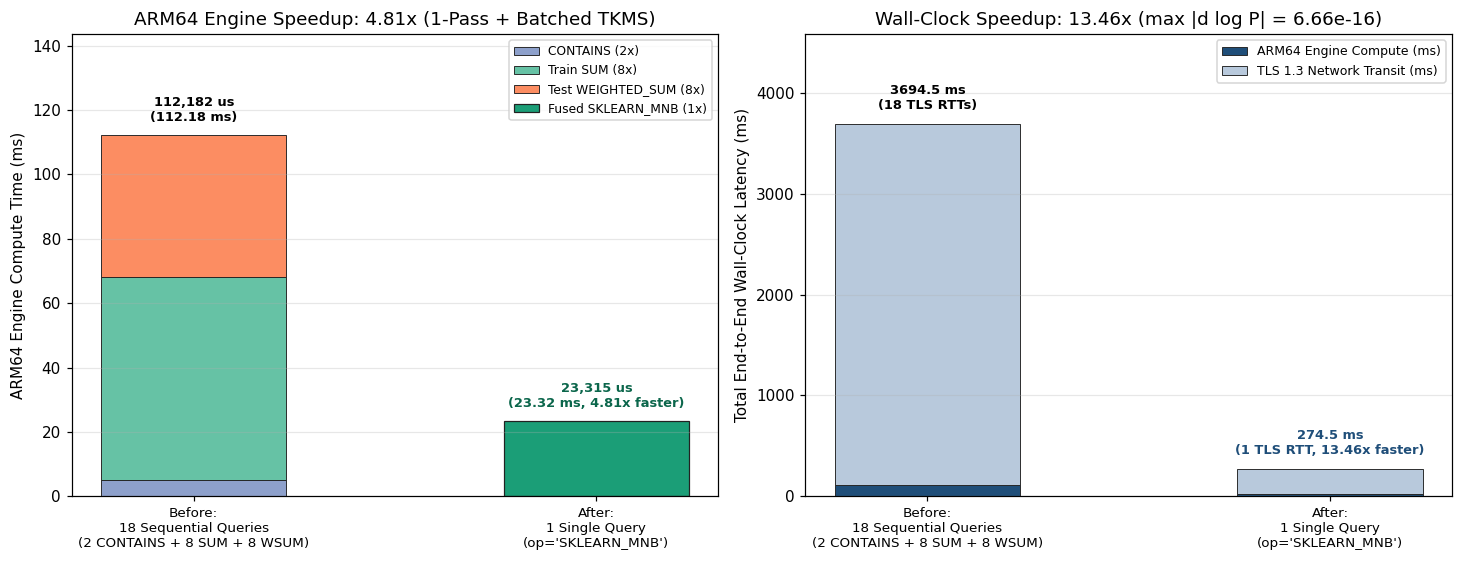

In [6]:
# Before (18 Sequential Queries) vs. After (1 Single SKLEARN_MNB Query) Speedup Chart
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.2), dpi=110)

# Left Panel: ARM64 Engine Compute Breakdown (ms)
eng_labels = ["Before:\n18 Sequential Queries\n(2 CONTAINS + 8 SUM + 8 WSUM)", "After:\n1 Single Query\n(op='SKLEARN_MNB')"]
x_pos = np.arange(2)
b_con = benchmark_summary["before_stage_eng_ms"]["CONTAINS (2x)"]
b_sum = benchmark_summary["before_stage_eng_ms"]["Train SUM (8x)"]
b_wsm = benchmark_summary["before_stage_eng_ms"]["Test WSUM (8x)"]
a_eng = benchmark_summary["after_eng_ms"]

axes[0].bar(x_pos[0], b_con, width=0.46, color="#8da0cb", edgecolor="#222222", linewidth=0.6, label="CONTAINS (2x)")
axes[0].bar(x_pos[0], b_sum, bottom=b_con, width=0.46, color="#66c2a5", edgecolor="#222222", linewidth=0.6, label="Train SUM (8x)")
axes[0].bar(x_pos[0], b_wsm, bottom=b_con + b_sum, width=0.46, color="#fc8d62", edgecolor="#222222", linewidth=0.6, label="Test WEIGHTED_SUM (8x)")
axes[0].bar(x_pos[1], a_eng, width=0.46, color="#1b9e77", edgecolor="#222222", linewidth=0.8, label="Fused SKLEARN_MNB (1x)")

eng_ymax = max(benchmark_summary["before_eng_ms"], a_eng) * 1.28
axes[0].set_ylim(0.0, eng_ymax)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(eng_labels, fontsize=8.8)
axes[0].set_ylabel("ARM64 Engine Compute Time (ms)")
axes[0].set_title(f"ARM64 Engine Speedup: {benchmark_summary['eng_speedup']:.2f}x (1-Pass + Batched TKMS)")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(loc="upper right", fontsize=8.0)

axes[0].text(
    x_pos[0],
    benchmark_summary["before_eng_ms"] + eng_ymax * 0.025,
    f"{benchmark_summary['before_eng_us']:,} us\n({benchmark_summary['before_eng_ms']:.2f} ms)",
    ha="center",
    va="bottom",
    fontsize=8.5,
    fontweight="bold",
)
axes[0].text(
    x_pos[1],
    a_eng + eng_ymax * 0.025,
    f"{benchmark_summary['after_eng_us']:,} us\n({a_eng:.2f} ms, {benchmark_summary['eng_speedup']:.2f}x faster)",
    ha="center",
    va="bottom",
    fontsize=8.5,
    fontweight="bold",
    color="#0b664b",
)

# Right Panel: Total End-to-End Wall-Clock Latency (ARM64 Engine + TLS 1.3 Network Transit)
eng_vals = [benchmark_summary["before_eng_ms"], benchmark_summary["after_eng_ms"]]
net_vals = [benchmark_summary["before_net_ms"], benchmark_summary["after_net_ms"]]
tot_vals = [benchmark_summary["before_rtt_ms"], benchmark_summary["after_rtt_ms"]]

axes[1].bar(x_pos, eng_vals, width=0.46, color="#1f4e79", edgecolor="#222222", linewidth=0.6, label="ARM64 Engine Compute (ms)")
axes[1].bar(x_pos, net_vals, bottom=eng_vals, width=0.46, color="#b8c9dc", edgecolor="#222222", linewidth=0.6, label="TLS 1.3 Network Transit (ms)")

rtt_ymax = max(tot_vals) * 1.24
axes[1].set_ylim(0.0, rtt_ymax)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(eng_labels, fontsize=8.8)
axes[1].set_ylabel("Total End-to-End Wall-Clock Latency (ms)")
axes[1].set_title(
    f"Wall-Clock Speedup: {benchmark_summary['rtt_speedup']:.2f}x "
    f"(max |d log P| = {max_lp_diff:.2e})"
)
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(loc="upper right", fontsize=8.2)

axes[1].text(
    x_pos[0],
    tot_vals[0] + rtt_ymax * 0.025,
    f"{tot_vals[0]:.1f} ms\n(18 TLS RTTs)",
    ha="center",
    va="bottom",
    fontsize=8.5,
    fontweight="bold",
)
axes[1].text(
    x_pos[1],
    tot_vals[1] + rtt_ymax * 0.025,
    f"{tot_vals[1]:.1f} ms\n(1 TLS RTT, {benchmark_summary['rtt_speedup']:.2f}x faster)",
    ha="center",
    va="bottom",
    fontsize=8.5,
    fontweight="bold",
    color="#1f4e79",
)

plt.tight_layout()
plt.show()


## 5. Production Security & Key-Custody Summary

- **Schema-Less Encrypted NoSQL (`BlindJSONB`):** Fixed-budget HMAC containment slots (`k_tok=8`) and lattice-encrypted numeric slots (`k_num=8`) prevent schema-size and sparsity side channels while supporting exact Postgres `@>` containment, `UPSERT` v2 superseding, `TOMBSTONE` deletion, and fused single-query `SKLEARN_MNB` training + cohort scoring.
- **Anti-Extraction Policy (`k_min_tkms`):** Enforcing `k_min_tkms >= 2` (and higher thresholds such as `k_min_tkms=16` in production) cryptographically blocks single-document extraction probes (`HTTP 422`) on both standalone `WEIGHTED_SUM` and every training class and scoring cohort inside `SKLEARN_MNB`.
- **Independent Verifiability (`NSAU0001`):** Every table creation, containment match, homomorphic aggregate, and single-query `SKLEARN_MNB` pipeline (`JSONB_SKLEARN_MNB`) returns a deterministic `NSAU0001` `SHA-256` receipt verified locally in pure Python without exposing plaintext documents.
